# Markov decision processes

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/05-reinforcement/mdp/mdp-notebook.ipynb)

Companion notebook for the *Markov decision processes* slides. Each idea is written first by hand
with NumPy and then checked with an independent computation that should give the same answer.

**Data:** no data set; the agent moves in the slippery 4 × 3 grid world (wall at (2, 2), goal +1, pit −1, each step −0.04).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

RANDOM_STATE = 42
GAMMA = 0.9
STEP_REWARD = -0.04
ARROWS = "↑→↓←"


class GridWorld:
    """The 4 × 3 grid world: wall at (2, 2), goal +1 at (4, 3), pit −1 at (4, 2), start at (1, 1)."""

    # (column, row), 0-based, without the wall
    cells = [(x, y) for y in range(3) for x in range(4) if (x, y) != (1, 1)]
    moves = [(0, 1), (1, 0), (0, -1), (-1, 0)]  # up, right, down, left

    def __init__(self, slip=0.2, step_reward=-0.04, random_state=None):
        self.slip = slip
        self.step_reward = step_reward
        self.rng = np.random.default_rng(random_state)
        self.n_states = len(self.cells)
        self.n_actions = len(self.moves)
        self.start = self.cells.index((0, 0))
        self.goal = self.cells.index((3, 2))
        self.pit = self.cells.index((3, 1))
        self.terminal = [self.goal, self.pit]
        self.P, self.R = self._model()

    def _move(self, s, direction):
        """Next cell when moving in a direction; hitting a wall means staying."""
        column, row = self.cells[s]
        d_column, d_row = self.moves[direction]
        cell = (column + d_column, row + d_row)
        return self.cells.index(cell) if cell in self.cells else s

    def _model(self):
        """Chances P[s, a, s'] and rewards R[s, a, s']; a terminal state stays put with reward 0."""
        P = np.zeros((self.n_states, self.n_actions, self.n_states))
        for s in range(self.n_states):
            for a in range(self.n_actions):
                if s in self.terminal:
                    P[s, a, s] = 1
                    continue
                outcomes = [
                    (a, 1 - self.slip),            # the intended direction
                    ((a + 1) % 4, self.slip / 2),  # slip 90° clockwise
                    ((a + 3) % 4, self.slip / 2),  # slip 90° counter-clockwise
                ]
                for direction, chance in outcomes:
                    P[s, a, self._move(s, direction)] += chance
        R = np.full(P.shape, self.step_reward)
        R[:, :, self.goal] = 1
        R[:, :, self.pit] = -1
        R[self.terminal] = 0
        return P, R

    def reset(self, state=None):
        """Start an episode in `state` (the start cell by default) and return it."""
        self.state = self.start if state is None else state
        return self.state

    def step(self, action):
        """Sample the next state from P and return (next_state, reward, done)."""
        next_state = self.rng.choice(self.n_states, p=self.P[self.state, action])
        reward = self.R[self.state, action, next_state]
        self.state = next_state
        return next_state, reward, next_state in self.terminal


env = GridWorld(slip=0.2, step_reward=STEP_REWARD, random_state=RANDOM_STATE)

## 1. The transition chances

One table $P(s' \mid s, a)$ describes all the dynamics, and each row is a distribution:
$\sum_{s'} P(s' \mid s, a) = 1$. Calling `step` many times should give the same chances (up to sampling noise).

In [2]:
print("every row sums to 1:", np.allclose(env.P.sum(axis=2), 1))

UP = 0
samples = []
for _ in range(10_000):
    env.reset()
    samples.append(env.step(UP)[0])
counts = np.bincount(samples, minlength=env.n_states)
frequencies = counts / len(samples)
for s in np.flatnonzero(env.P[env.start, UP]):
    column, row = env.cells[s]
    chance = env.P[env.start, UP, s]
    print(f"start, up -> cell {column + 1, row + 1}: chance {chance:.1f}")
print("same result:", np.allclose(frequencies, env.P[env.start, UP], atol=0.02))

every row sums to 1: True
start, up -> cell (1, 1): chance 0.1
start, up -> cell (2, 1): chance 0.1
start, up -> cell (1, 2): chance 0.8
same result: True


## 2. The return

$G_t = \sum_k \gamma^k R_{t+k+1} = R_{t+1} + \gamma\, G_{t+1}$. The deck's robot episode with rewards +2, +2, −3:
the direct sum and the backward recursion agree.

In [3]:
rewards = np.array([2, 2, -3])
discounts = GAMMA ** np.arange(len(rewards))  # γ^k
return_by_sum = np.sum(discounts * rewards)

return_by_recursion = 0
for r in rewards[::-1]:
    return_by_recursion = r + GAMMA * return_by_recursion

print(f"G_0 = {return_by_sum:.2f} | same result:", np.isclose(return_by_sum, return_by_recursion))

G_0 = 1.37 | same result: True


## 3. Policy evaluation

For a fixed policy $\pi(s)$ the Bellman equation is
$V^\pi(s) = \sum_{s'} P(s' \mid s, \pi(s)) \big[R(s, \pi(s), s') + \gamma V^\pi(s')\big]$.
Sweeping it from $V = 0$ converges; since it is linear in $V^\pi$, `np.linalg.solve` also gives it exactly.

In [4]:
class PolicyEvaluation:
    """Sweep the Bellman equation of a fixed policy until the values stop changing."""

    def __init__(self, gamma=0.9, tol=1e-10):
        self.gamma = gamma
        self.tol = tol

    def fit(self, env, policy):
        rows = np.arange(env.n_states)
        P_pi = env.P[rows, policy]  # P(s' | s, π(s)), one row per state s
        R_pi = env.R[rows, policy]  # R(s, π(s), s')
        V = np.zeros(env.n_states)
        while True:
            # V(s) = Σ_s' P(s' | s, π(s)) [R(s, π(s), s') + γ V(s')], for every s at once
            backup = R_pi + self.gamma * V  # R(s, π(s), s') + γ V(s')
            V_new = (P_pi * backup).sum(axis=1)  # weight by P(s' | s, π(s)), sum over s'
            if np.max(np.abs(V_new - V)) < self.tol:
                break
            V = V_new
        self.values_ = V_new
        return self

In [5]:
policy = np.array([0, 3, 0, 3,  # bottom row: up, left, up, left
                   0, 0, 0,     # middle row: up, up, (pit)
                   1, 1, 1, 0])  # top row: right, right, right, (goal)
evaluation = PolicyEvaluation(gamma=GAMMA).fit(env, policy)

# The Bellman equation in matrix form: (I − γ P_π) V = r_π, with r_π(s) = Σ_s' P R
rows = np.arange(env.n_states)
P_pi = env.P[rows, policy]
R_pi = env.R[rows, policy]
r_pi = (P_pi * R_pi).sum(axis=1)
I = np.eye(env.n_states)
V_solve = np.linalg.solve(I - GAMMA * P_pi, r_pi)
V_start = evaluation.values_[env.start]
print(f"V(start) = {V_start:.3f} | same result:", np.allclose(evaluation.values_, V_solve))

V(start) = 0.369 | same result: True


## 4. Value iteration and policy iteration

Value iteration repeats $V_{k+1}(s) = \max_a \sum_{s'} P(s' \mid s, a)\big[R(s, a, s') + \gamma V_k(s')\big]$
and reads the greedy policy $\pi^*(s) = \arg\max_a Q^*(s, a)$.
Policy iteration (evaluate the policy, then act greedily, repeat) should reach the same $V^*$ and $\pi^*$.

In [6]:
class ValueIteration:
    """Repeat the Bellman optimality update, then act greedily on Q*."""

    def __init__(self, gamma=0.9, tol=1e-10):
        self.gamma = gamma
        self.tol = tol

    def fit(self, env):
        V = np.zeros(env.n_states)
        self.n_iter_ = 0
        while True:
            # Q(s, a) = Σ_s' P(s' | s, a) [R(s, a, s') + γ V_k(s')], for every s and a at once
            backup = env.R + self.gamma * V  # R(s, a, s') + γ V_k(s')
            Q = (env.P * backup).sum(axis=2)  # weight by P(s' | s, a), sum over s'
            V_new = Q.max(axis=1)  # V_{k+1}(s) = max_a Q(s, a)
            self.n_iter_ += 1
            if np.max(np.abs(V_new - V)) < self.tol:
                break
            V = V_new
        self.values_ = V_new
        self.q_values_ = Q
        self.policy_ = Q.argmax(axis=1)  # π*(s) = argmax_a Q*(s, a)
        return self

    def predict(self, state):
        return self.policy_[state]


class PolicyIteration:
    """Evaluate the policy, make it greedy for those values, and repeat until it stops changing."""

    def __init__(self, gamma=0.9, tol=1e-10):
        self.gamma = gamma
        self.tol = tol

    def fit(self, env):
        policy = np.full(env.n_states, 3)  # start from "always go left"
        self.n_iter_ = 0
        while True:
            V = PolicyEvaluation(self.gamma, self.tol).fit(env, policy).values_  # evaluate
            backup = env.R + self.gamma * V  # R(s, a, s') + γ V(s')
            Q = (env.P * backup).sum(axis=2)  # Q(s, a) = Σ_s' P(s' | s, a) [...]
            improved = Q.argmax(axis=1)  # act greedily: argmax_a Q(s, a)
            self.n_iter_ += 1
            if np.array_equal(improved, policy):
                break
            policy = improved
        self.values_ = V
        self.policy_ = policy
        return self

    def predict(self, state):
        return self.policy_[state]

In [7]:
value_iteration = ValueIteration(gamma=GAMMA).fit(env)
policy_iteration = PolicyIteration(gamma=GAMMA).fit(env)

non_terminal = [s for s in range(env.n_states) if s not in env.terminal]
print(f"value iteration: {value_iteration.n_iter_} sweeps | "
      f"policy iteration: {policy_iteration.n_iter_} rounds")
print("same values:", np.allclose(value_iteration.values_, policy_iteration.values_, atol=1e-8))
policy_by_values = value_iteration.predict(non_terminal)
policy_by_policies = policy_iteration.predict(non_terminal)
print("same policy:", np.array_equal(policy_by_values, policy_by_policies))

value iteration: 32 sweeps | policy iteration: 4 rounds
same values: True
same policy: True


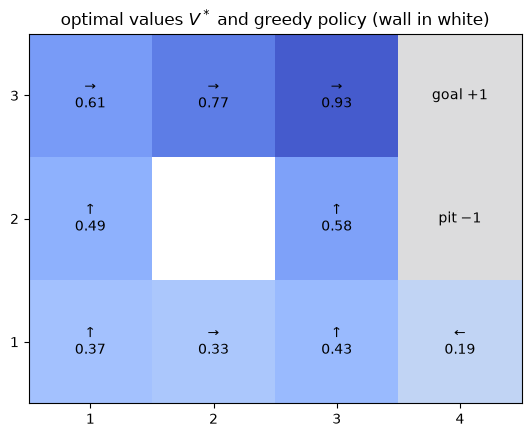

In [8]:
grid = np.full((3, 4), np.nan)
for s, (x, y) in enumerate(env.cells):
    grid[y, x] = value_iteration.values_[s]
    if s == env.goal:
        label = "goal +1"
    elif s == env.pit:
        label = "pit −1"
    else:
        arrow = ARROWS[value_iteration.predict(s)]
        label = f"{arrow}\n{value_iteration.values_[s]:.2f}"
    plt.text(x, y, label, ha="center", va="center")
plt.imshow(grid, origin="lower", cmap="coolwarm_r", vmin=-1, vmax=1)
plt.xticks(range(4), range(1, 5))
plt.yticks(range(3), range(1, 4))
plt.title("optimal values $V^*$ and greedy policy (wall in white)")
plt.show()

## Exercises

1. Set `STEP_REWARD = -2` and rerun the notebook. Why does the agent now head for the pit from some cells?
2. Evaluate the policy "always go right" with `PolicyEvaluation` and compare its $V(\text{start})$ with $V^*(\text{start})$.
3. Compare `ValueIteration(gamma).fit(env).n_iter_` for $\gamma = 0.5$ and for $\gamma = 0.99$.